In [ ]:
# Import necessary libraries

# Basics
import itertools
import re
from IPython.display import display, Markdown
import warnings
from numpy.linalg import LinAlgError
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# For DLNM
from statsmodels.gam.gam_cross_validation.cross_validators import KFold
import statsmodels.api as sm
from statsmodels.gam.smooth_basis import UnivariateBSplines, UnivariateCubicCyclicSplines
from statsmodels.gam.api import GLMGam, BSplines, CyclicCubicSplines
from statsmodels.genmod.families.links import log
from statsmodels.gam.smooth_basis import GenericSmoothers
from pydlnm.basis import CrossBasis
from pydlnm.prediction import crosspred
from dlnm import crossbasis, plot_crosspred, cb_pen

# Testing
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [15]:
def cb_construct(dataframe, col_lst, max_lag, setting_lst):
    var_degree, var_df, lag_degree, lag_df = setting_lst

    cb_list = []
    for col in col_lst:
        cb = CrossBasis(
            dataframe[col].values, lag=max_lag,
            argvar={"fun": "bs", "degree": var_degree, "df": var_df},
            arglag={"fun": "bs", "degree": lag_degree, "df": lag_df},
        )
        cb_list.append(cb)

    X_exposure = np.concatenate([np.asarray(cb) for cb in cb_list], axis=1)

    n_basis_per_exp = X_exposure.shape[1] // len(col_lst)
    exp_name_list = [f"{col}_basis_{i}" for col in col_lst for i in range(n_basis_per_exp)]

    base = dataframe.reset_index(drop=True).iloc[max_lag:].copy()
    basis_df = pd.DataFrame(X_exposure[max_lag:], columns=exp_name_list, index=base.index)

    model_data = pd.concat([base, basis_df], axis=1)
    return model_data, exp_name_list, cb_list

In [16]:
def smoother_construct(dataframe, bs_dict, ccs_dict):
    bs_list = []
    for i, name in enumerate(bs_dict["name"]):
        bs = UnivariateBSplines(dataframe[name].values, df=bs_dict["df"][i], degree=bs_dict["degree"][i], variable_name=name, include_intercept=False)
        bs_list.append(bs)

    ccs_list = []
    for i, name in enumerate(ccs_dict["name"]):
        ccs = UnivariateCubicCyclicSplines(dataframe[name].values, df=ccs_dict["df"][i], variable_name=name, constraints="center")
        ccs_list.append(ccs)

    sm_weights = bs_list + ccs_list
    smooth_names = list(bs_dict["name"]) + list(ccs_dict["name"])
    X_smooth = dataframe[smooth_names]
    
    return GenericSmoothers(X_smooth, sm_weights)

In [17]:
def model_construct(dataframe, tar_var, exp_names, linear_predictors, smoothers, alpha, disp_para):
    terms = list(exp_names) + list(linear_predictors)
    formula = f"{tar_var} ~ {' + '.join(terms)}"

    alpha = np.asarray(alpha, dtype=float)

    model = GLMGam.from_formula(formula, data=dataframe, smoother=smoothers, alpha=alpha, family=sm.families.NegativeBinomial(alpha=disp_para))
    result = model.fit()
    
    return model, result


In [ ]:
def cb_tune(dataframe, tar_var, exp_col, linear_predictors, bs_dict, ccs_dict, alpha, disp_para, max_lag, grid):
    print(f"{'='*10} Tuning CrossBasis settings {'='*10}")
    best_idx = 0
    performance = []

    for option in grid:
        model_data, exp_names, _ = cb_construct(dataframe, exp_col, max_lag, option)
        # Rebuild smoothers on the lagged-truncated data
        smoothers = smoother_construct(model_data, bs_dict, ccs_dict)
        try:
            _, result = model_construct(
                model_data, tar_var, exp_names, linear_predictors,
                smoothers, alpha, disp_para,
            )
            bic = result.bic
        except Exception as e:
            print(f"\toption {option} failed: {e}")
            bic = np.inf
        performance.append(bic)
        print(f"\tBIC for {option}: {bic:.2f}" if np.isfinite(bic) else f"  BIC for {option}: failed")

    for i in range(1, len(performance)):
        if performance[i] < performance[best_idx]:
            best_idx = i

    best_setting = grid[best_idx]
    print(f"Best CrossBasis setting: {best_setting} (BIC={performance[best_idx]:.2f})")
    return cb_construct(dataframe, exp_col, max_lag, best_setting)

In [19]:
def smoother_tune(dataframe, tar_var, exp_names, linear_predictors, alpha, disp_para, bs_name_lst, ccs_name_lst, grid):
    print(f"\n{'='*10} Tuning smoother degrees of freedom {'='*10}")
    n_bs = len(bs_name_lst)
    best_idx = 0
    performance = []

    for option in grid:
        bs_dfs = list(option[:n_bs])
        ccs_dfs = list(option[n_bs:])

        bs_dict = {"name": bs_name_lst, "degree": [3] * n_bs, "df": bs_dfs}
        ccs_dict = {"name": ccs_name_lst, "df": ccs_dfs}

        smoothers = smoother_construct(dataframe, bs_dict, ccs_dict)
        try:
            _, result = model_construct(
                dataframe, tar_var, exp_names, linear_predictors,
                smoothers, alpha, disp_para,
            )
            bic = result.bic
            edf = float(np.sum(result.edf))
        except Exception as e:
            print(f"  option {option} failed: {e}")
            bic, edf = np.inf, np.nan

        performance.append((bic, edf))
        print(f"  dfs={option}  BIC={bic:.2f}  sum(EDF)={edf:.2f}")

    for i in range(1, len(performance)):
        if performance[i][0] < performance[best_idx][0]:
            best_idx = i

    best_option = grid[best_idx]
    print(f"Best smoother dfs: {best_option} (BIC={performance[best_idx][0]:.2f})")

    # Rebuild and return the winning smoothers + the dicts used
    bs_dict = {"name": bs_name_lst, "degree": [3] * n_bs, "df": list(best_option[:n_bs])}
    ccs_dict = {"name": ccs_name_lst,"df": list(best_option[n_bs:])}

    return smoother_construct(dataframe, bs_dict, ccs_dict), bs_dict, ccs_dict

In [20]:
def alpha_tune(dataframe, tar_var, exp_names, linear_predictors, smoothers, start_alpha, disp_para, criterion="bic", method="nm"):
    print(f"\n{'='*10} Tuning smoother weights (alpha) {'='*10}")

    start_alpha = np.asarray(start_alpha, dtype=float)
    model, result = model_construct(dataframe, tar_var, exp_names, linear_predictors, smoothers, start_alpha, disp_para)
    best_alpha = model.select_penweight(criterion=criterion, method=method, start_params=start_alpha)

    # Normalise return value to a 1-d float array
    if isinstance(best_alpha, (list, tuple)):
        candidate = best_alpha[0]
        alpha_out = np.asarray(candidate if np.ndim(candidate) > 0 else best_alpha, dtype=float)
    else:
        alpha_out = np.asarray(best_alpha, dtype=float).ravel()

    print(f"Best alpha found with {criterion}: {alpha_out}")
    return alpha_out


In [21]:
def disp_tune(dataframe, tar_var, exp_names, linear_predictors, smoothers, alpha, disp_grid):
    print(f"\n{'='*10} Tuning Negative Binomial dispersion parameter {'='*10}")
    performance = []

    for disp in disp_grid:
        try:
            _, result = model_construct(
                dataframe, tar_var, exp_names, linear_predictors,
                smoothers, alpha, disp,
            )
            pearson_ratio = result.pearson_chi2 / result.df_resid
            performance.append((disp, pearson_ratio, result.bic))
            print(f"  disp={disp:5.1f} → Pearson χ²/df = {pearson_ratio:.3f} | BIC = {result.bic:.1f}")
        except Exception as e:
            print(f"  disp={disp} failed: {e}")

    if not performance:
        raise RuntimeError("All dispersion values failed.")

    best = min(performance, key=lambda x: abs(x[1] - 1.0))
    print(f"\nBest dispersion parameter: {best[0]} (Pearson ratio = {best[1]:.3f})")
    return best[0]

In [22]:
def pred_cal(result, cb_list, dataframe, exp_col_list, exp_idx=0):
    exp = exp_col_list[exp_idx]
    param_names = list(result.params.index)
    basis_names = [n for n in param_names if n.startswith(f"{exp}_basis_")]
    if not basis_names:
        raise ValueError(f"No basis coefficients found for exposure '{exp}'.")

    cb_coef = result.params[basis_names].values
    cb_vcov = result.cov_params().loc[basis_names, basis_names].values

    at = np.linspace(dataframe[exp].min(), dataframe[exp].max(), 100)
    cen = float(dataframe[exp].median())

    pred = crosspred(
        basis=cb_list[exp_idx],
        coef=cb_coef,
        vcov=cb_vcov,
        model_link="log",
        at=at,
        cen=cen
    )
    print(f"{exp} RR range: {pred.allRRfit.min():.3f} to {pred.allRRfit.max():.3f}")
    
    return pred, exp, cen

In [23]:
def graph_3Dplot(pred, exp_name):
    if plot_crosspred is None:
        print("plot_crosspred not available; skipping 3-D plot.")
        return

    fig = plot_crosspred(pred, ptype="3d")
    ax = fig.gca()
    ax.set_title("3D Exposure-Lag-Response Association Surface", fontsize=14, fontweight="bold", pad=15)
    ax.set_xlabel(exp_name, fontsize=12, labelpad=10)
    ax.set_ylabel("Lag (Weeks)", fontsize=12, labelpad=10)
    ax.set_zlabel("Relative Risk (RR)", labelpad=10)

    if hasattr(pred, "matRRfit"):
        ax.set_yticks(np.linspace(0, pred.matRRfit.shape[1] - 1, min(5, pred.matRRfit.shape[1])))

    try:
        collections = ax.collections[0]
        vmin, vmax = collections.get_array().min(), collections.get_array().max()
        collections.set_clim(vmin, vmax)
        cbar = fig.colorbar(collections, ax=ax, shrink=0.6, pad=0.1)
        cbar.set_label("Relative Risk (RR)", rotation=270, labelpad=20)
    except Exception:
        pass

    plt.tight_layout()
    plt.show()


def graph_exp_plot(pred, exp_name, cen):
    if plot_crosspred is None:
        # Simple fallback
        fig, ax = plt.subplots(figsize=(7, 4))
        ax.plot(pred.at, pred.allRRfit, color="C0", lw=2)
        if hasattr(pred, "allRRlow") and hasattr(pred, "allRRhigh"):
            ax.fill_between(pred.at, pred.allRRlow, pred.allRRhigh, alpha=0.25, color="C0")
        ax.axhline(1, color="gray", ls="--", alpha=0.7)
        ax.axvline(cen, color="black", ls=":", lw=1.2, label=f"Centering {exp_name} ({cen:.4f})")
        ax.set_title("Overall Cumulative Exposure-Response Association", fontsize=14, pad=12)
        ax.set_xlabel(exp_name, fontsize=12)
        ax.set_ylabel("Relative Risk (RR)", fontsize=12)
        ax.legend(loc="best")
        plt.tight_layout()
        plt.show()
        return

    fig = plot_crosspred(pred, ptype="overall")
    ax = fig.gca()
    ax.axvline(x=cen, color="black", linestyle=":", linewidth=1.2, label=f"Centering {exp_name} ({cen:.4f})")
    ax.set_title("Overall Cumulative Exposure-Response Association", fontsize=14, pad=15)
    ax.set_xlabel(exp_name, fontsize=12)
    ax.legend(loc="best", frameon=True)
    plt.show()


def graph_lag_plot(pred, tar_val, exp_name):
    if plot_crosspred is None:
        print("plot_crosspred not available; skipping lag-slice plot.")
        return

    fig = plot_crosspred(pred, ptype="slices", var=tar_val)
    ax = fig.gca()
    ax.set_title(f"Lag-Response Curve at {exp_name} = {tar_val:.4f}",
                 fontsize=14, fontweight="bold")
    ax.set_xlabel("Lag (Weeks)", fontsize=12)
    ax.set_ylabel("Relative Risk (RR)", fontsize=12)
    ax.axhline(1, color="gray", linestyle="--", alpha=0.7)
    plt.show()


def graph_plot(pred, exp_name, cen, lag_slice_val=None):
    graph_3Dplot(pred, exp_name)
    graph_exp_plot(pred, exp_name, cen)
    if lag_slice_val is None:
        lag_slice_val = cen
    graph_lag_plot(pred, lag_slice_val, exp_name)

In [24]:
def model_metric(result):
    print(f"AIC: {result.aic}")
    print(f"BIC: {result.bic}")
    print(f"Deviance: {result.deviance}")
    print(f"Pearson Chi2: {result.pearson_chi2}")
    print(f"Scale/Dispersion: {result.scale}")
    print(f"Effective degree of freedom: \n{result.edf}")
    print(f"Total EDF: {result.edf.sum()}")

In [25]:
def residual_diagnostics(result):
    residuals = result.resid_deviance

    # 1. Residuals vs. Fitted Values Plot (checks for systematic bias)
    plt.figure(figsize=(8, 4))
    plt.scatter(result.fittedvalues, residuals, alpha=0.3)
    plt.axhline(0, color='red', linestyle='--')
    plt.xlabel("Fitted Values")
    plt.ylabel("Deviance Residuals")
    plt.title("Residuals vs Fitted")
    plt.show()

    # 2. Autocorrelation Check (ACF) - Vital for time series!
    # Time-series data often has uncaptured temporal patterns; residuals should look like white noise.
    fig, ax = plt.subplots(figsize=(8, 4))
    sm.graphics.tsa.plot_acf(residuals, lags=10, ax=ax)
    plt.title("Autocorrelation of Residuals (ACF)")
    plt.show()

In [26]:
def DLNM(dataframe, max_lag, tar_var, exp_col_list, linear_predictors_list, bs_name_lst, ccs_name_lst, cb_grid, smoother_grid, disp_grid, criterion="bic"):
    n_smooth = len(bs_name_lst) + len(ccs_name_lst)

    initial_cb_setting = [2, 3, 2, 3]  
    initial_alpha = np.asarray([200.0] * n_smooth, dtype=float)
    initial_disp = 1.0

    init_bs_dict = {"name": bs_name_lst, "degree": [3] * len(bs_name_lst), "df": [6] * len(bs_name_lst)}
    init_ccs_dict = {"name": ccs_name_lst, "df": [4] * len(ccs_name_lst)}

    model_data, exp_name_list, cb_list = cb_tune(dataframe, tar_var, exp_col_list, linear_predictors_list, init_bs_dict, init_ccs_dict, initial_alpha, initial_disp, max_lag, cb_grid)
    smoothers, bs_dict, ccs_dict = smoother_tune(model_data, tar_var, exp_name_list, linear_predictors_list, initial_alpha, initial_disp, bs_name_lst, ccs_name_lst, smoother_grid)
    best_alpha = alpha_tune(model_data, tar_var, exp_name_list, linear_predictors_list, smoothers, initial_alpha, initial_disp, criterion=criterion, method="nm")
    best_disp = disp_tune(model_data, tar_var, exp_name_list, linear_predictors_list, smoothers, best_alpha, disp_grid)

    model, result = model_construct(model_data, tar_var, exp_name_list, linear_predictors_list, smoothers, best_alpha, best_disp)
    print(f"\n\n{'='*15} Final model summary {'='*15}")
    print(result.summary())

    model_metric(result)
    residual_diagnostics(result)

    pred, exp_name, cen = pred_cal(result, cb_list, model_data, exp_col_list, exp_idx=0)
    graph_plot(pred, exp_name, cen, lag_slice_val=cen)

    return result, pred, model_data, cb_list


---

In [27]:
# Most common sources of the message
warnings.filterwarnings("ignore", message=".*Singular matrix.*")
warnings.filterwarnings("ignore", message=".*singular matrix.*")
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="statsmodels")

In [28]:
# Import data and basic settings
df = pd.read_csv("data.csv")
df.columns = ["Year", "Week", "From", "temprange", "temp", "RH", "SR", "AP", "DPT", "WS", "UV", "H1", "H3", "B", "AandB", "ContainmentHealthIndex_Average", "pandemic_flag",]

# Drop unnecessary columns
df.drop(columns=["From"], inplace=True)

df["time"] = np.arange(1, len(df) + 1)

mete_col = ["temprange", "temp", "RH", "SR", "AP", "DPT", "WS", "UV"]
flu_col = ["H1", "H3", "B", "AandB"]
spline_col = ["ContainmentHealthIndex_Average", "Week", "time"]

In [29]:
# Overview
display(df.head())
print(df.info())
display(df.describe())

,Year,Week,temprange,temp,RH,SR,AP,DPT,WS,UV,H1,H3,B,AandB,ContainmentHealthIndex_Average,pandemic_flag,time
0,2002,36,14.3,28.15,76.5,19.66,1008.20,23.20,7.35,4.0,1,12,3.0,19,0.0,0.0,1
1,2002,37,13.6,26.70,85.0,9.35,1006.30,23.80,10.50,3.0,0,6,4.0,15,0.0,0.0,2
2,2002,38,11.2,26.40,83.0,16.75,1011.35,23.20,13.45,4.0,0,4,4.0,13,0.0,0.0,3
3,2002,39,10.0,25.90,85.0,10.93,1012.90,23.25,13.25,3.0,0,2,6.0,10,0.0,0.0,4
4,2002,40,10.6,25.95,82.0,11.56,1012.80,22.40,10.05,3.0,0,6,2.0,8,0.0,0.0,5


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1253 entries, 0 to 1252
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Year                            1253 non-null   int64  
 1   Week                            1253 non-null   int64  
 2   temprange                       1253 non-null   float64
 3   temp                            1253 non-null   float64
 4   RH                              1253 non-null   float64
 5   SR                              1253 non-null   float64
 6   AP                              1253 non-null   float64
 7   DPT                             1253 non-null   float64
 8   WS                              1253 non-null   float64
 9   UV                              1253 non-null   float64
 10  H1                              1253 non-null   int64  
 11  H3                              1253 non-null   int64  
 12  B                               12

,Year,Week,temprange,temp,RH,SR,AP,DPT,WS,UV,H1,H3,B,AandB,ContainmentHealthIndex_Average,pandemic_flag,time
count,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1252.000000,1253.000000,1253.000000,1253.000000,1253.000000
mean,2014.172386,26.605746,14.864006,23.383599,78.736233,13.996983,1012.860774,19.225339,10.074062,2.891700,69.613727,115.727055,44.593450,261.437350,8.128132,0.131684,627.000000
std,6.945058,15.077257,3.539967,5.005770,8.494599,5.270534,6.067874,5.963239,1.811932,1.256406,189.083854,233.728958,131.615377,439.621172,21.983305,0.338282,361.854252
min,2002.000000,1.000000,3.900000,8.900000,43.000000,2.020000,996.750000,-0.100000,5.550000,0.400000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2008.000000,14.000000,12.200000,19.100000,74.500000,9.930000,1008.000000,14.900000,8.800000,2.000000,0.000000,5.000000,3.000000,27.000000,0.000000,0.000000,314.000000
50%,2014.000000,27.000000,14.000000,24.400000,80.000000,14.240000,1012.800000,20.500000,10.000000,3.000000,4.000000,28.000000,12.500000,103.000000,0.000000,0.000000,627.000000
75%,2020.000000,40.000000,17.000000,28.000000,85.000000,17.680000,1017.650000,24.800000,11.200000,4.000000,47.000000,125.000000,41.000000,305.000000,0.000000,0.000000,940.000000
max,2026.000000,53.000000,27.700000,31.700000,94.000000,26.460000,1027.700000,26.800000,17.800000,7.000000,1999.000000,2560.000000,1978.000000,4679.000000,82.140000,1.000000,1253.000000


In [30]:
linear_predictors_list = ["pandemic_flag"]
bs_name_lst = ["time", "ContainmentHealthIndex_Average"]
ccs_name_lst = ["Week"]

cb_grid = list(itertools.product([2, 3], [3, 4, 5, 6], [2, 3], [3, 4, 5]))
smoother_grid = list(itertools.product([5, 6, 7], [4, 5, 6], [3, 4]))
disp_grid = [1.0, 2.0, 5.0, 10.0, 20.0]

**============================== temprange ==============================**


========== Tuning CrossBasis settings ==========


	BIC for (2, 3, 2, 3): 9624.99
	BIC for (2, 3, 2, 4): 9647.52
	BIC for (2, 3, 2, 5): 9670.04
	BIC for (2, 3, 3, 3): 9647.52
	BIC for (2, 3, 3, 4): 9647.52
	BIC for (2, 3, 3, 5): 9670.04
	BIC for (2, 4, 2, 3): 9632.58
	BIC for (2, 4, 2, 4): 9662.67
	BIC for (2, 4, 2, 5): 9693.55
	BIC for (2, 4, 3, 3): 9662.67
	BIC for (2, 4, 3, 4): 9662.67
	BIC for (2, 4, 3, 5): 9693.55
	BIC for (2, 5, 2, 3): 9628.66
	BIC for (2, 5, 2, 4): 9667.71
	BIC for (2, 5, 2, 5): 9707.19
	BIC for (2, 5, 3, 3): 9667.71
	BIC for (2, 5, 3, 4): 9667.71
	BIC for (2, 5, 3, 5): 9707.19
	BIC for (2, 6, 2, 3): 9653.72
	BIC for (2, 6, 2, 4): 9700.76
	BIC for (2, 6, 2, 5): 9746.89
	BIC for (2, 6, 3, 3): 9700.76
	BIC for (2, 6, 3, 4): 9700.76
	BIC for (2, 6, 3, 5): 9746.89
	BIC for (3, 3, 2, 3): 9626.60
	BIC for (3, 3, 2, 4): 9649.95
	BIC for (3, 3, 2, 5): 9672.47
	BIC for (3, 3, 3, 3): 9649.95
	BIC for (3, 3, 3, 4): 9649.95
	BIC for (3, 3, 3, 5): 9672.47
	BIC for (3, 4, 2, 3): 9643.91
	BIC for (3, 4, 2, 4): 9675.51
	BIC for

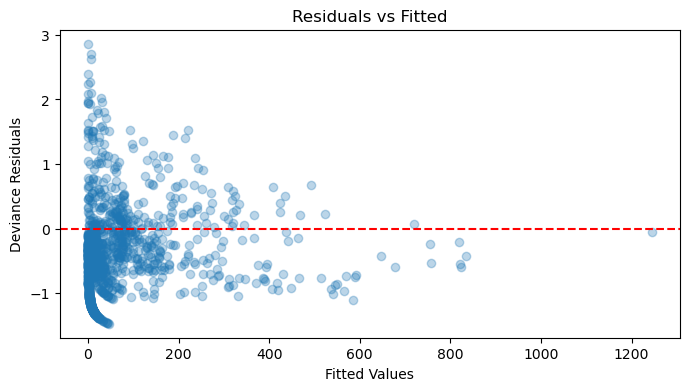

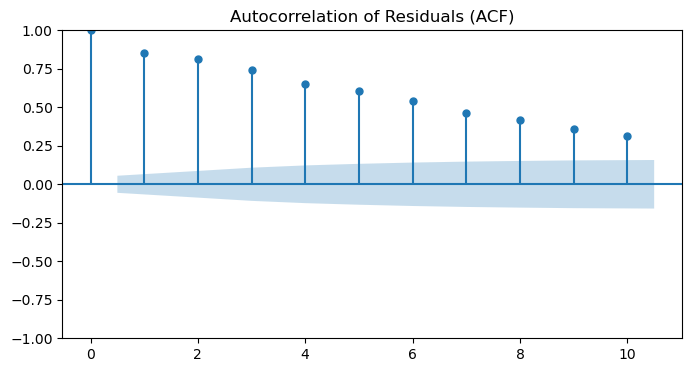

temprange RR range: 0.936 to 59416.373


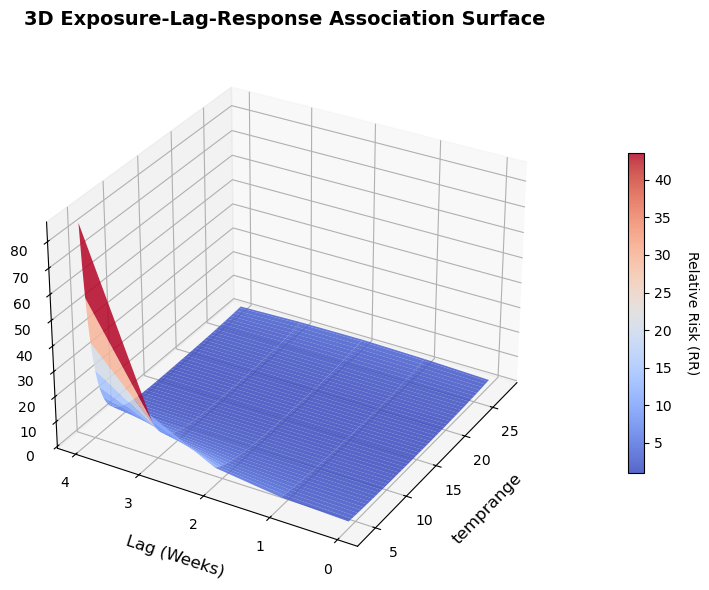

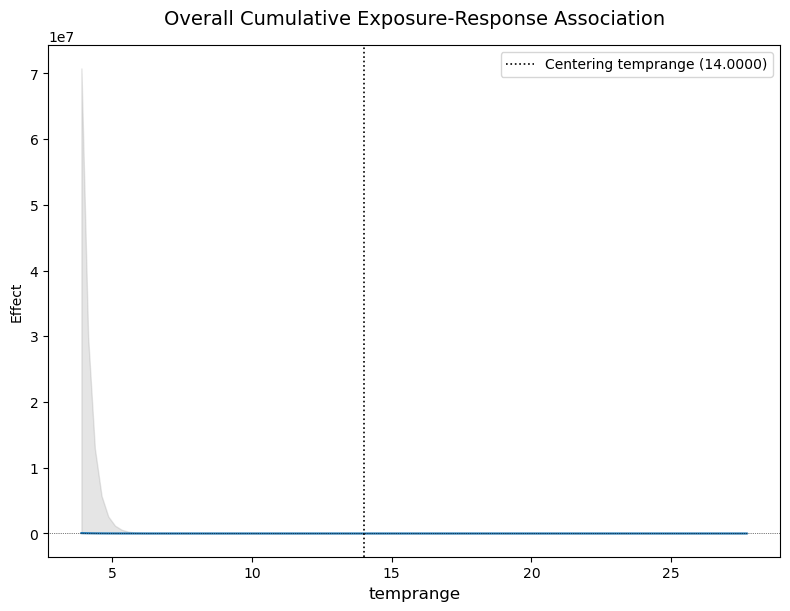

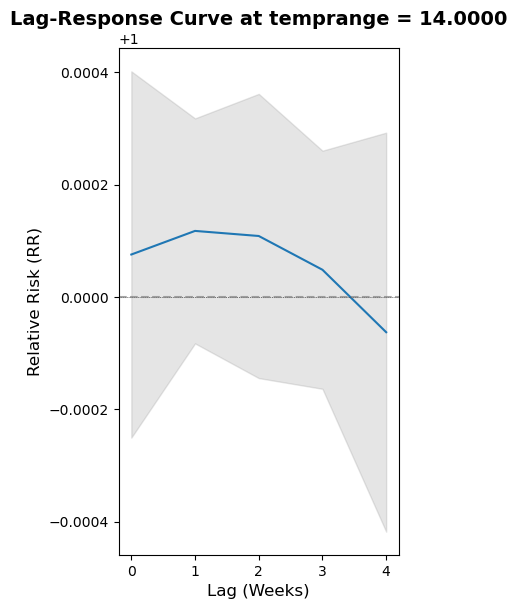

**============================== temp ==============================**


========== Tuning CrossBasis settings ==========
	BIC for (2, 3, 2, 3): 9385.20
	BIC for (2, 3, 2, 4): 9408.07
	BIC for (2, 3, 2, 5): 9427.80
	BIC for (2, 3, 3, 3): 9408.07
	BIC for (2, 3, 3, 4): 9408.07
	BIC for (2, 3, 3, 5): 9427.80
	BIC for (2, 4, 2, 3): 9399.10
	BIC for (2, 4, 2, 4): 9429.47
	BIC for (2, 4, 2, 5): 9457.52
	BIC for (2, 4, 3, 3): 9429.47
	BIC for (2, 4, 3, 4): 9429.47
	BIC for (2, 4, 3, 5): 9457.52
	BIC for (2, 5, 2, 3): 9438.48
	BIC for (2, 5, 2, 4): 9460.09
	BIC for (2, 5, 2, 5): 9494.31
	BIC for (2, 5, 3, 3): 9460.09
	BIC for (2, 5, 3, 4): 9460.09
	BIC for (2, 5, 3, 5): 9494.31
	BIC for (2, 6, 2, 3): 9442.59
	BIC for (2, 6, 2, 4): 9492.34
	BIC for (2, 6, 2, 5): 9513.29
	BIC for (2, 6, 3, 3): 9492.34
	BIC for (2, 6, 3, 4): 9492.34
	BIC for (2, 6, 3, 5): 9513.29
	BIC for (3, 3, 2, 3): 9387.82
	BIC for (3, 3, 2, 4): 9411.95
	BIC for (3, 3, 2, 5): 9433.63
	BIC for (3, 3, 3, 3): 9411.95
	BIC for (3, 3, 3, 4): 9411.95
	BIC for (3, 3, 3, 5): 9433.63
	BIC for (3, 4, 2, 3

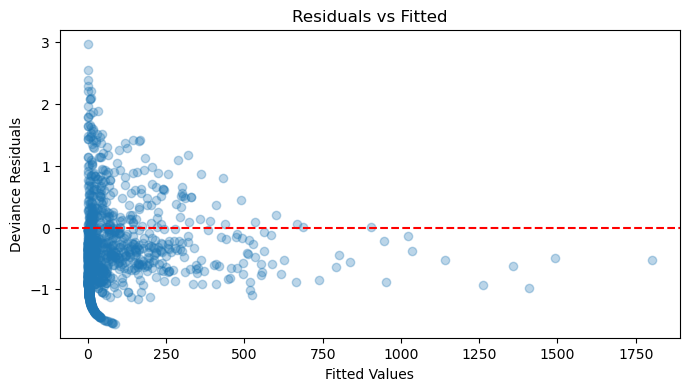

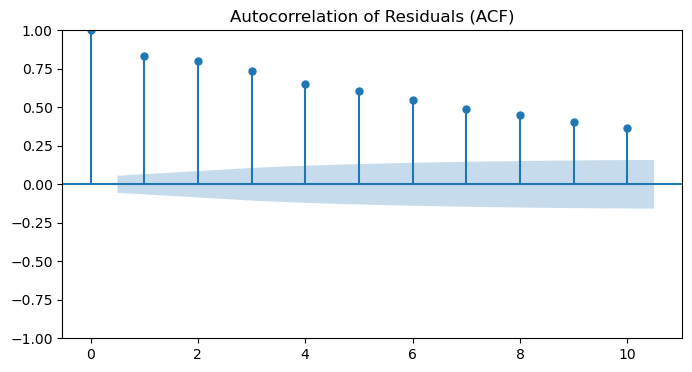

temp RR range: 0.978 to 1086.485


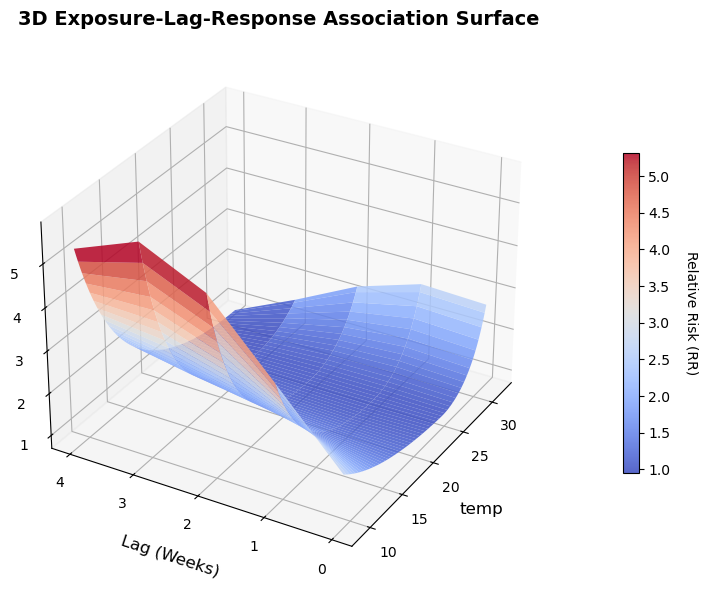

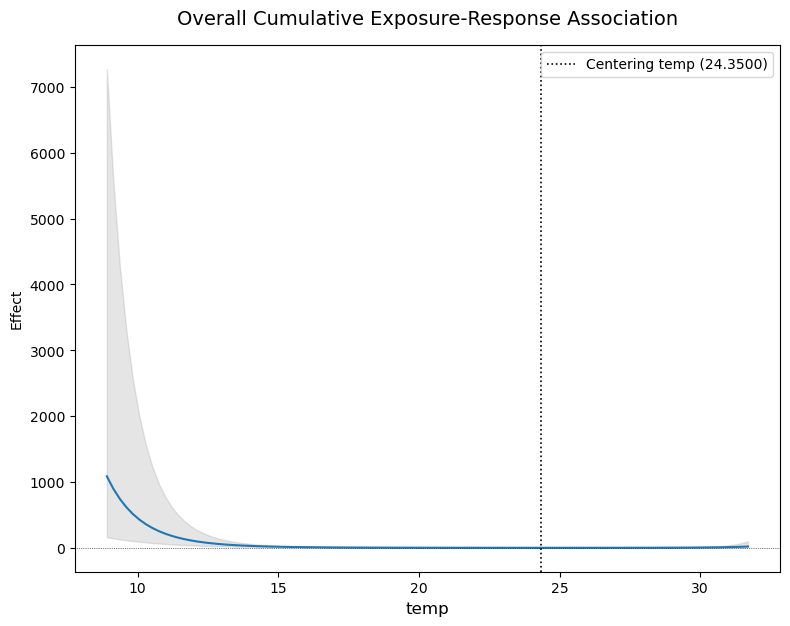

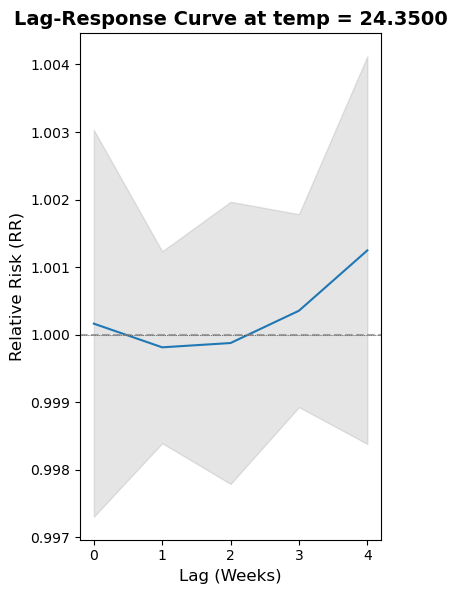

**============================== RH ==============================**


========== Tuning CrossBasis settings ==========
	BIC for (2, 3, 2, 3): 9765.95
	BIC for (2, 3, 2, 4): 9786.12
	BIC for (2, 3, 2, 5): 9805.21
	BIC for (2, 3, 3, 3): 9786.12
	BIC for (2, 3, 3, 4): 9786.12
	BIC for (2, 3, 3, 5): 9805.21
	BIC for (2, 4, 2, 3): 9741.92
	BIC for (2, 4, 2, 4): 9765.65
	BIC for (2, 4, 2, 5): 9789.51
	BIC for (2, 4, 3, 3): 9765.65
	BIC for (2, 4, 3, 4): 9765.65
	BIC for (2, 4, 3, 5): 9789.51
	BIC for (2, 5, 2, 3): 9677.51
	BIC for (2, 5, 2, 4): 9708.79
	BIC for (2, 5, 2, 5): 9739.86
	BIC for (2, 5, 3, 3): 9708.79
	BIC for (2, 5, 3, 4): 9708.79
	BIC for (2, 5, 3, 5): 9739.86
	BIC for (2, 6, 2, 3): 9632.88
	BIC for (2, 6, 2, 4): 9669.79
	BIC for (2, 6, 2, 5): 9705.75
	BIC for (2, 6, 3, 3): 9669.79
	BIC for (2, 6, 3, 4): 9669.79
	BIC for (2, 6, 3, 5): 9705.75
	BIC for (3, 3, 2, 3): 9753.66
	BIC for (3, 3, 2, 4): 9772.90
	BIC for (3, 3, 2, 5): 9790.35
	BIC for (3, 3, 3, 3): 9772.90
	BIC for (3, 3, 3, 4): 9772.90
	BIC for (3, 3, 3, 5): 9790.35
	BIC for (3, 4, 2, 3

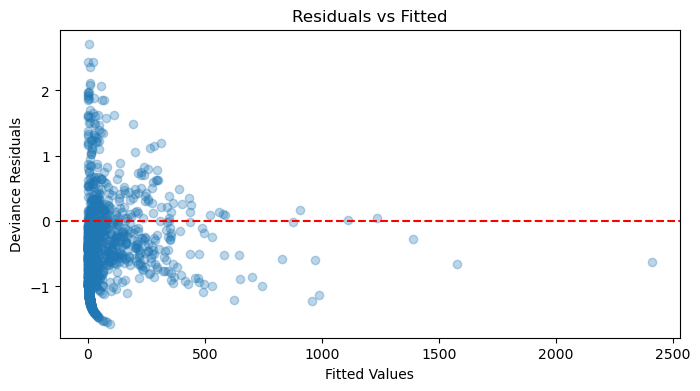

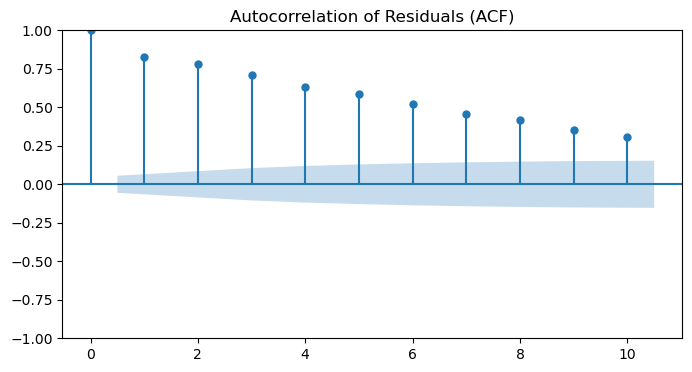

RH RR range: 0.335 to 6249.825


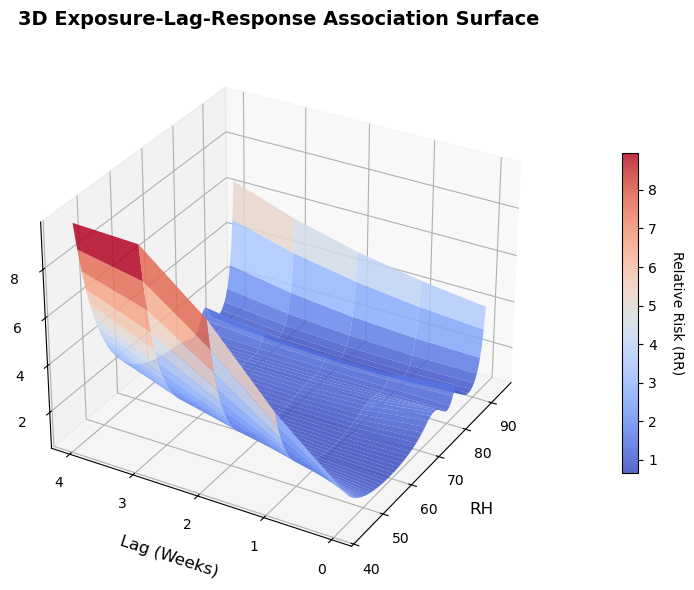

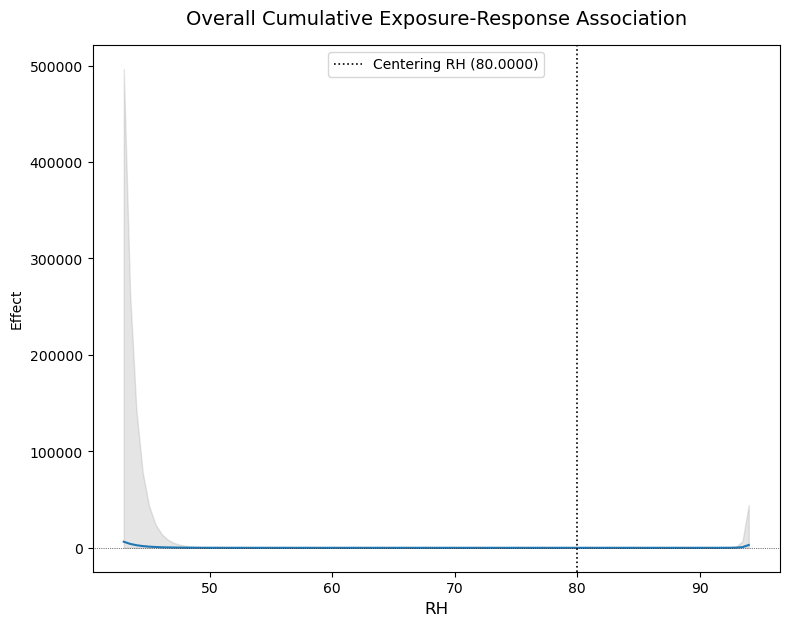

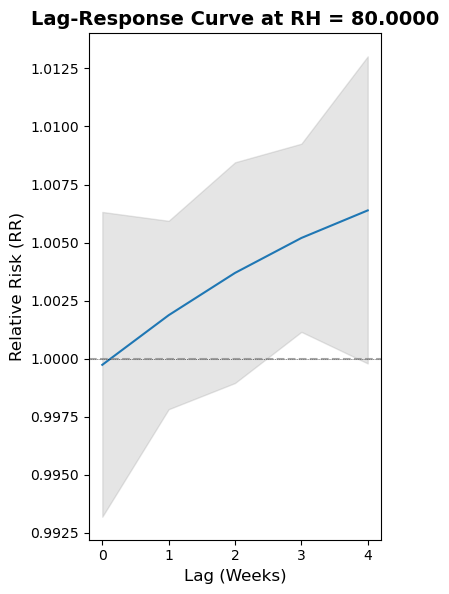

**============================== SR ==============================**


========== Tuning CrossBasis settings ==========
	BIC for (2, 3, 2, 3): 9722.47
	BIC for (2, 3, 2, 4): 9746.33
	BIC for (2, 3, 2, 5): 9770.89
	BIC for (2, 3, 3, 3): 9746.33
	BIC for (2, 3, 3, 4): 9746.33
	BIC for (2, 3, 3, 5): 9770.89
	BIC for (2, 4, 2, 3): 9743.57
	BIC for (2, 4, 2, 4): 9773.89
	BIC for (2, 4, 2, 5): 9803.34
	BIC for (2, 4, 3, 3): 9773.89
	BIC for (2, 4, 3, 4): 9773.89
	BIC for (2, 4, 3, 5): 9803.34
	BIC for (2, 5, 2, 3): 9752.21
	BIC for (2, 5, 2, 4): 9788.11
	BIC for (2, 5, 2, 5): 9822.52
	BIC for (2, 5, 3, 3): 9788.11
	BIC for (2, 5, 3, 4): 9788.11
	BIC for (2, 5, 3, 5): 9822.52
	BIC for (2, 6, 2, 3): 9757.41
	BIC for (2, 6, 2, 4): 9800.07
	BIC for (2, 6, 2, 5): 9843.09
	BIC for (2, 6, 3, 3): 9800.07
	BIC for (2, 6, 3, 4): 9800.07
	BIC for (2, 6, 3, 5): 9843.09
	BIC for (3, 3, 2, 3): 9724.63
	BIC for (3, 3, 2, 4): 9748.34
	BIC for (3, 3, 2, 5): 9772.96
	BIC for (3, 3, 3, 3): 9748.34
	BIC for (3, 3, 3, 4): 9748.34
	BIC for (3, 3, 3, 5): 9772.96
	BIC for (3, 4, 2, 3

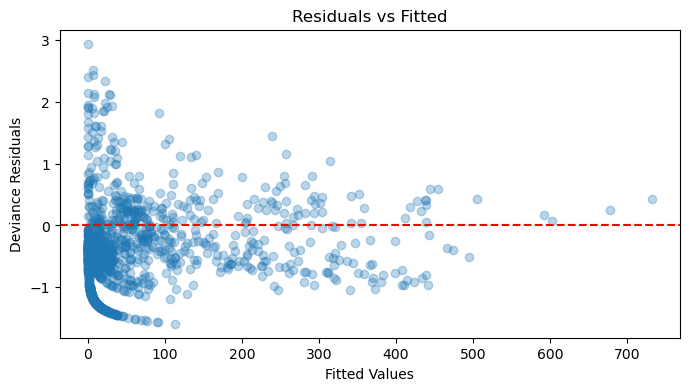

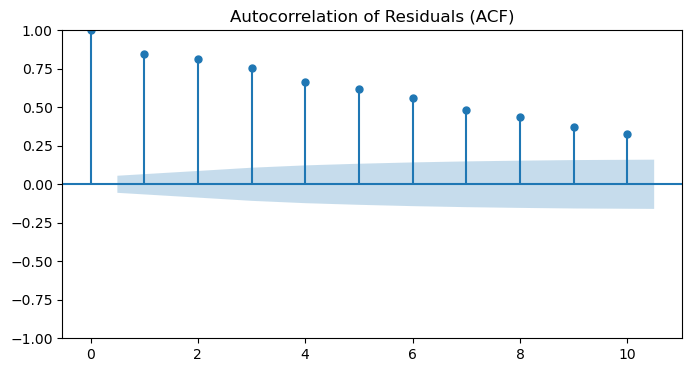

SR RR range: 0.241 to 31.736


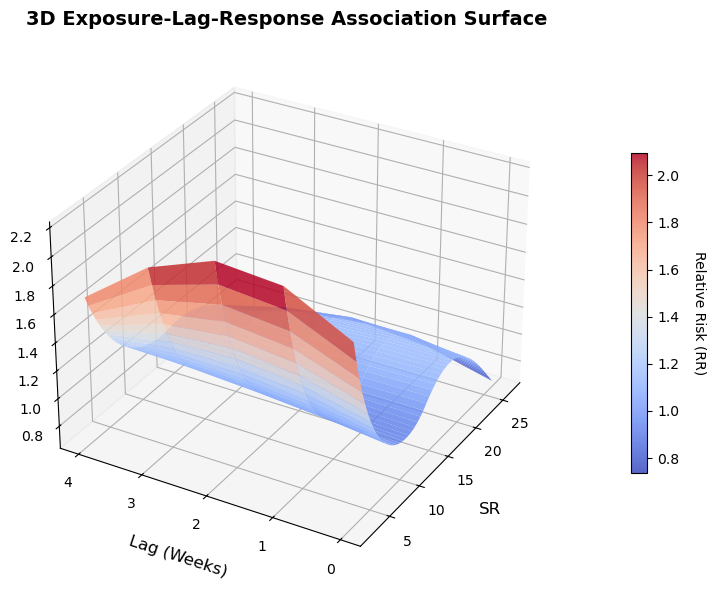

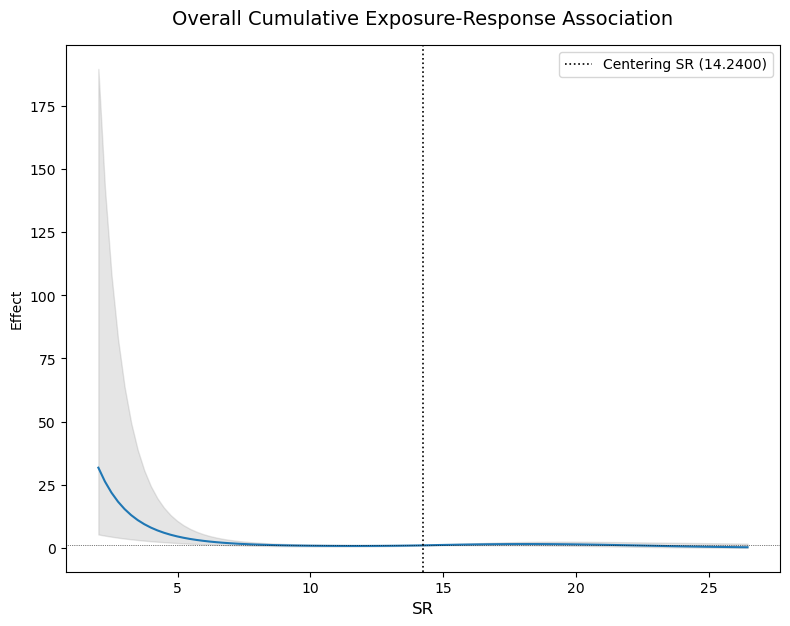

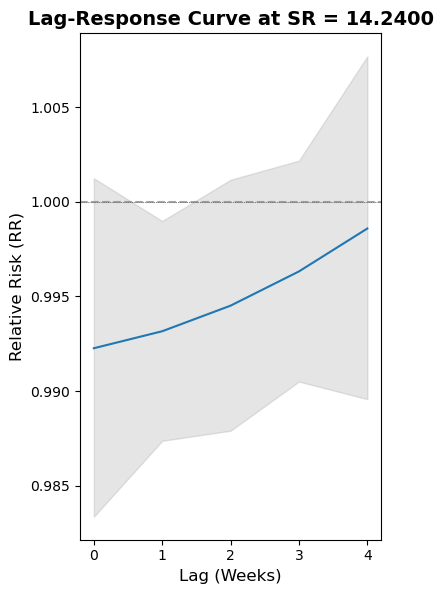

**============================== AP ==============================**


========== Tuning CrossBasis settings ==========
	BIC for (2, 3, 2, 3): 9511.99
	BIC for (2, 3, 2, 4): 9536.16
	BIC for (2, 3, 2, 5): 9557.47
	BIC for (2, 3, 3, 3): 9536.16
	BIC for (2, 3, 3, 4): 9536.16
	BIC for (2, 3, 3, 5): 9557.47
	BIC for (2, 4, 2, 3): 9540.52
	BIC for (2, 4, 2, 4): 9571.84
	BIC for (2, 4, 2, 5): 9617.78
	BIC for (2, 4, 3, 3): 9571.84
	BIC for (2, 4, 3, 4): 9571.84
	BIC for (2, 4, 3, 5): 9617.78
	BIC for (2, 5, 2, 3): 9553.07
	BIC for (2, 5, 2, 4): 9590.27
	BIC for (2, 5, 2, 5): 9647.06
	BIC for (2, 5, 3, 3): 9590.27
	BIC for (2, 5, 3, 4): 9590.27
	BIC for (2, 5, 3, 5): 9647.06
	BIC for (2, 6, 2, 3): 9541.95
	BIC for (2, 6, 2, 4): 9587.09
	BIC for (2, 6, 2, 5): 9648.57
	BIC for (2, 6, 3, 3): 9587.09
	BIC for (2, 6, 3, 4): 9587.09
	BIC for (2, 6, 3, 5): 9648.57
	BIC for (3, 3, 2, 3): 9531.33
	BIC for (3, 3, 2, 4): 9556.65
	BIC for (3, 3, 2, 5): 9584.26
	BIC for (3, 3, 3, 3): 9556.65
	BIC for (3, 3, 3, 4): 9556.65
	BIC for (3, 3, 3, 5): 9584.26
	BIC for (3, 4, 2, 3

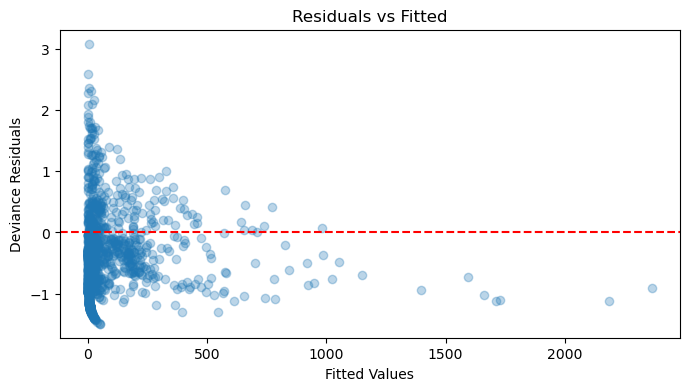

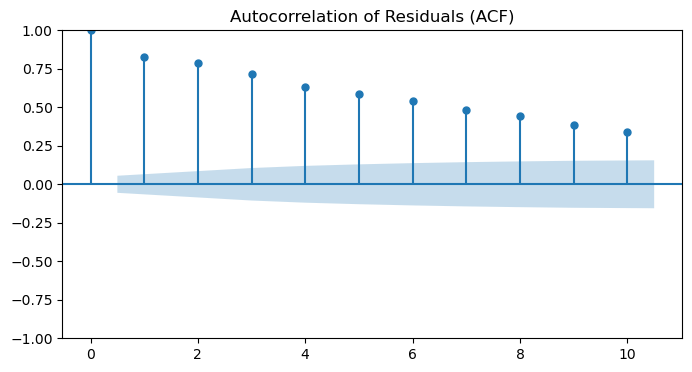

AP RR range: 0.724 to 1546.563


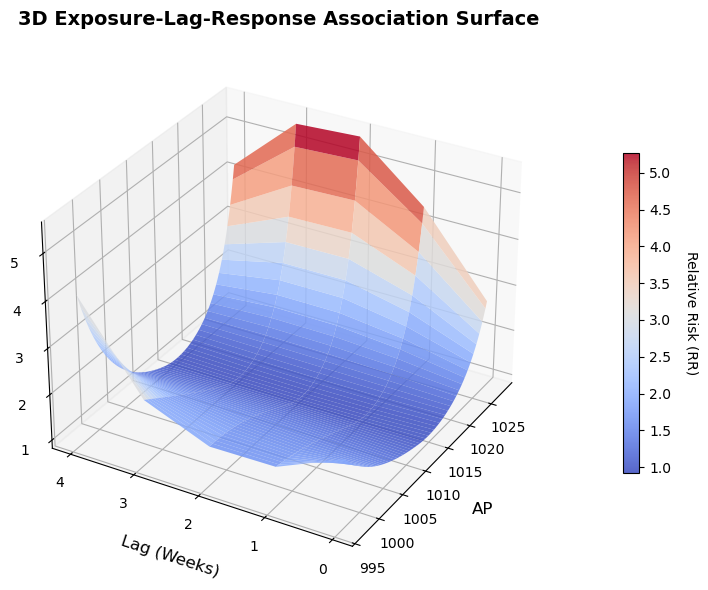

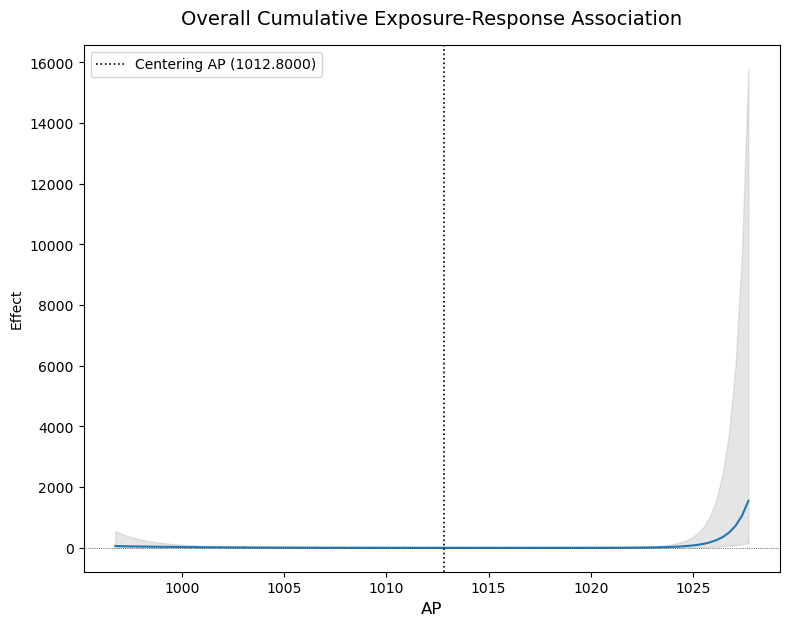

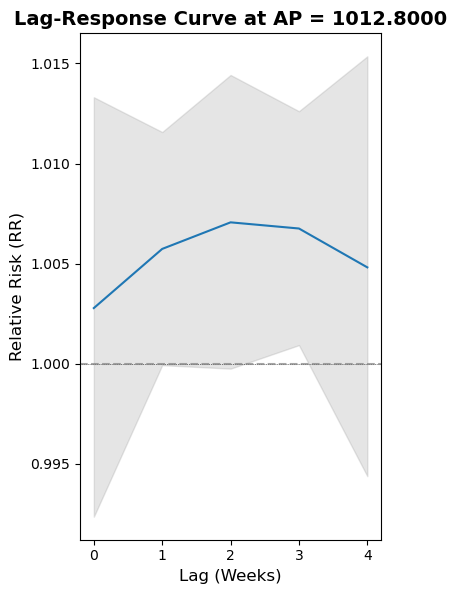

**============================== DPT ==============================**


========== Tuning CrossBasis settings ==========
	BIC for (2, 3, 2, 3): 9399.26
	BIC for (2, 3, 2, 4): 9417.72
	BIC for (2, 3, 2, 5): 9434.93
	BIC for (2, 3, 3, 3): 9417.72
	BIC for (2, 3, 3, 4): 9417.72
	BIC for (2, 3, 3, 5): 9434.93
	BIC for (2, 4, 2, 3): 9420.64
	BIC for (2, 4, 2, 4): 9444.51
	BIC for (2, 4, 2, 5): 9467.76
	BIC for (2, 4, 3, 3): 9444.51
	BIC for (2, 4, 3, 4): 9444.51
	BIC for (2, 4, 3, 5): 9467.76
	BIC for (2, 5, 2, 3): 9431.30
	BIC for (2, 5, 2, 4): 9462.32
	BIC for (2, 5, 2, 5): 9491.05
	BIC for (2, 5, 3, 3): 9462.32
	BIC for (2, 5, 3, 4): 9462.32
	BIC for (2, 5, 3, 5): 9491.05
	BIC for (2, 6, 2, 3): 9451.67
	BIC for (2, 6, 2, 4): 9490.23
	BIC for (2, 6, 2, 5): 9525.77
	BIC for (2, 6, 3, 3): 9490.23
	BIC for (2, 6, 3, 4): 9490.23
	BIC for (2, 6, 3, 5): 9525.77
	BIC for (3, 3, 2, 3): 9396.06
	BIC for (3, 3, 2, 4): 9414.97
	BIC for (3, 3, 2, 5): 9432.83
	BIC for (3, 3, 3, 3): 9414.97
	BIC for (3, 3, 3, 4): 9414.97
	BIC for (3, 3, 3, 5): 9432.83
	BIC for (3, 4, 2, 3

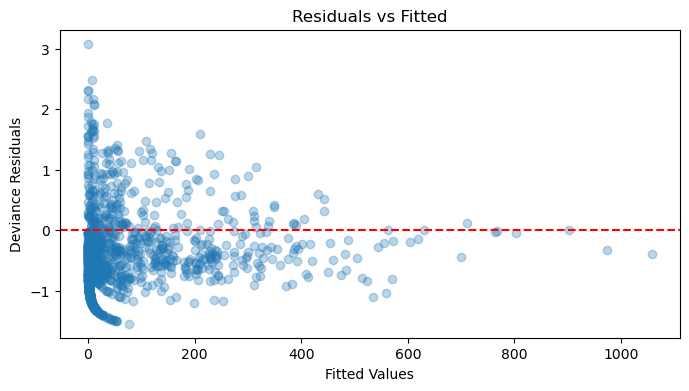

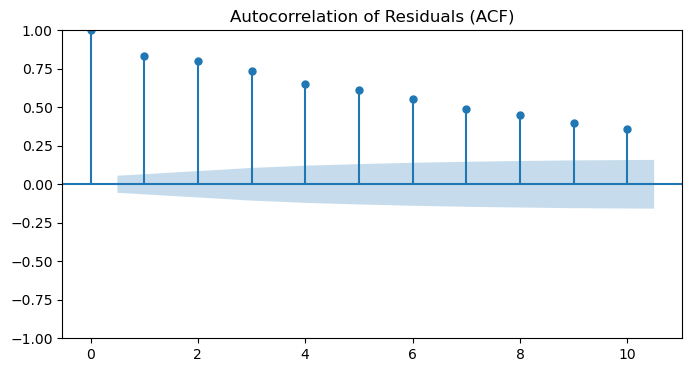

DPT RR range: 0.638 to 81.733


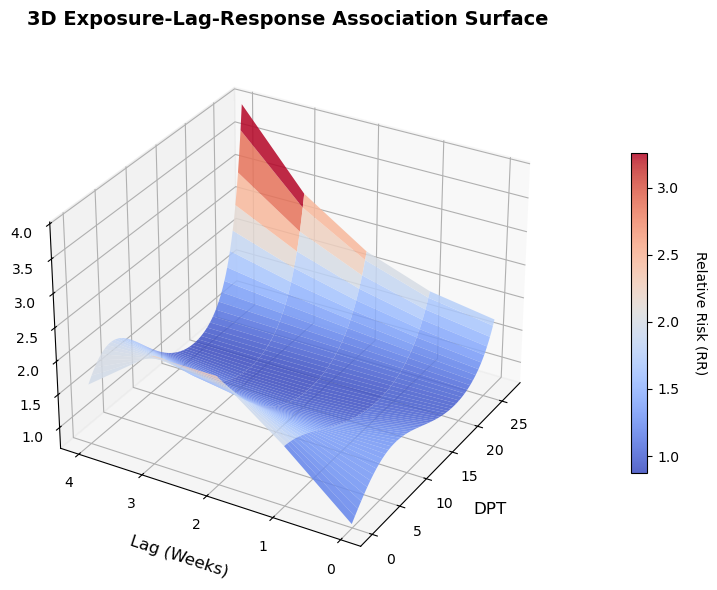

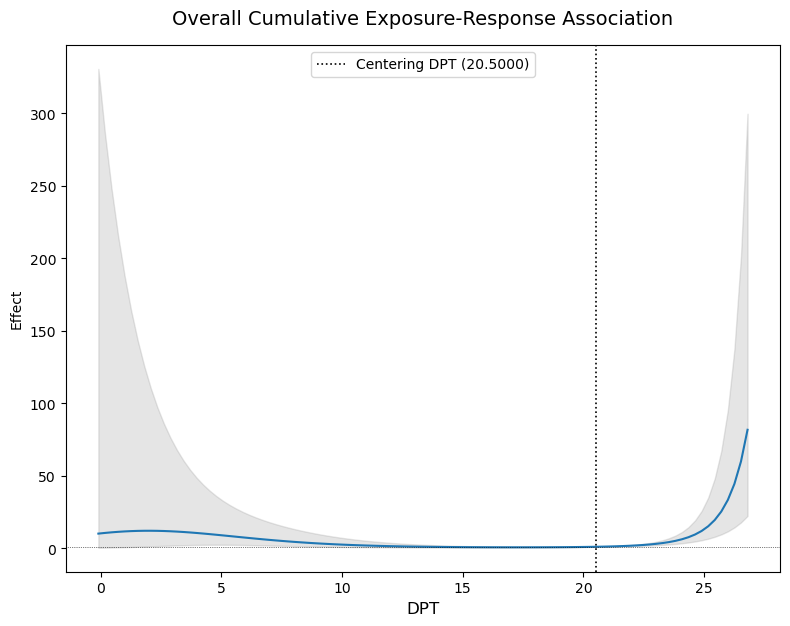

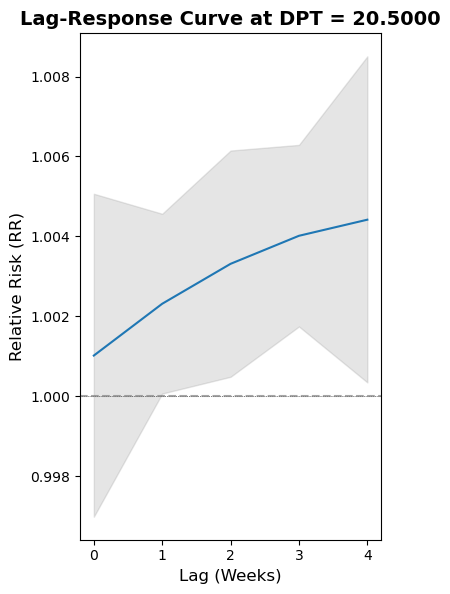

**============================== WS ==============================**


========== Tuning CrossBasis settings ==========
	BIC for (2, 3, 2, 3): 9747.56
	BIC for (2, 3, 2, 4): 9767.51
	BIC for (2, 3, 2, 5): 9786.27
	BIC for (2, 3, 3, 3): 9767.51
	BIC for (2, 3, 3, 4): 9767.51
	BIC for (2, 3, 3, 5): 9786.27
	BIC for (2, 4, 2, 3): 9761.73
	BIC for (2, 4, 2, 4): 9789.14
	BIC for (2, 4, 2, 5): 9814.90
	BIC for (2, 4, 3, 3): 9789.14
	BIC for (2, 4, 3, 4): 9789.14
	BIC for (2, 4, 3, 5): 9814.90
	BIC for (2, 5, 2, 3): 9736.05
	BIC for (2, 5, 2, 4): 9772.52
	BIC for (2, 5, 2, 5): 9804.57
	BIC for (2, 5, 3, 3): 9772.52
	BIC for (2, 5, 3, 4): 9772.52
	BIC for (2, 5, 3, 5): 9804.57
	BIC for (2, 6, 2, 3): 9749.05
	BIC for (2, 6, 2, 4): 9794.20
	BIC for (2, 6, 2, 5): 9832.87
	BIC for (2, 6, 3, 3): 9794.20
	BIC for (2, 6, 3, 4): 9794.20
	BIC for (2, 6, 3, 5): 9832.87
	BIC for (3, 3, 2, 3): 9738.87
	BIC for (3, 3, 2, 4): 9759.46
	BIC for (3, 3, 2, 5): 9779.06
	BIC for (3, 3, 3, 3): 9759.46
	BIC for (3, 3, 3, 4): 9759.46
	BIC for (3, 3, 3, 5): 9779.06
	BIC for (3, 4, 2, 3

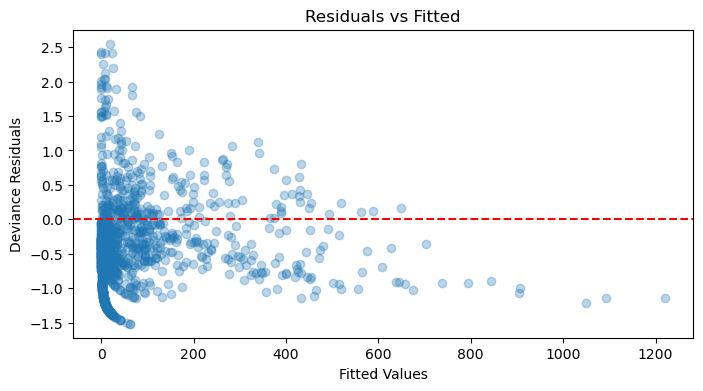

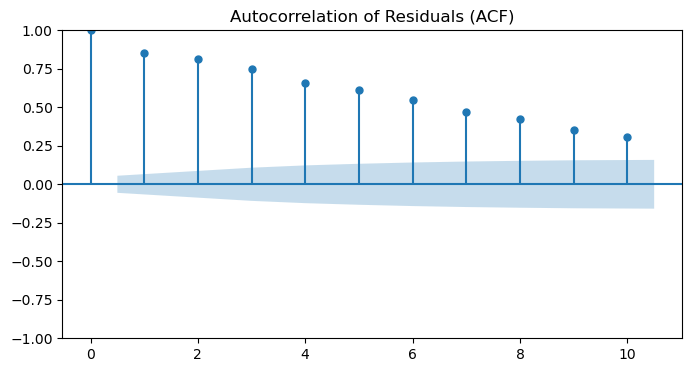

WS RR range: 0.506 to 456.280


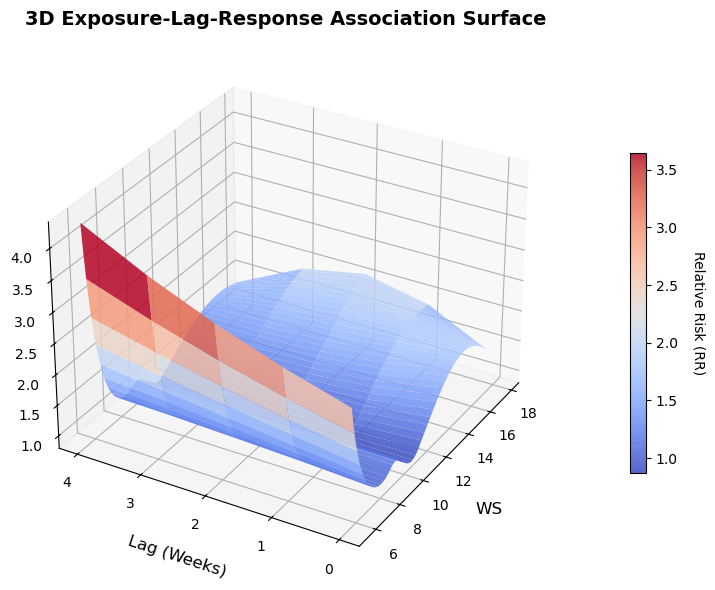

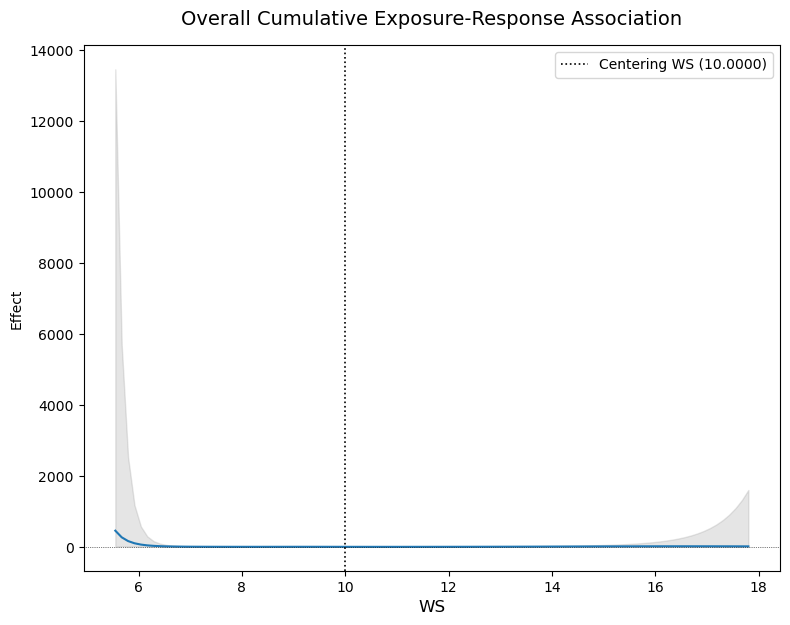

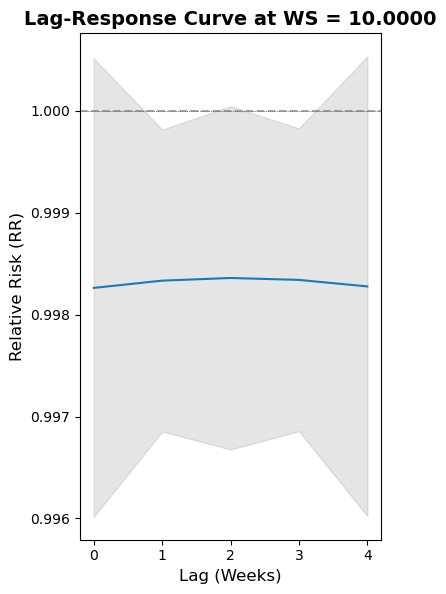

**============================== UV ==============================**


========== Tuning CrossBasis settings ==========
	BIC for (2, 3, 2, 3): 9694.33
	BIC for (2, 3, 2, 4): 9715.92
	BIC for (2, 3, 2, 5): 9738.42
	BIC for (2, 3, 3, 3): 9715.92
	BIC for (2, 3, 3, 4): 9715.92
	BIC for (2, 3, 3, 5): 9738.42
	BIC for (2, 4, 2, 3): 9677.75
	BIC for (2, 4, 2, 4): 9709.32
	BIC for (2, 4, 2, 5): 9739.70
	BIC for (2, 4, 3, 3): 9709.32
	BIC for (2, 4, 3, 4): 9709.32
	BIC for (2, 4, 3, 5): 9739.70
	BIC for (2, 5, 2, 3): 9640.96
	BIC for (2, 5, 2, 4): 9680.84
	BIC for (2, 5, 2, 5): 9720.07
	BIC for (2, 5, 3, 3): 9680.84
	BIC for (2, 5, 3, 4): 9680.84
	BIC for (2, 5, 3, 5): 9720.07
	BIC for (2, 6, 2, 3): 9640.00
	BIC for (2, 6, 2, 4): 9685.08
	BIC for (2, 6, 2, 5): 9729.05
	BIC for (2, 6, 3, 3): 9685.08
	BIC for (2, 6, 3, 4): 9685.08
	BIC for (2, 6, 3, 5): 9729.05
	BIC for (3, 3, 2, 3): 9680.41
	BIC for (3, 3, 2, 4): 9702.65
	BIC for (3, 3, 2, 5): 9725.67
	BIC for (3, 3, 3, 3): 9702.65
	BIC for (3, 3, 3, 4): 9702.65
	BIC for (3, 3, 3, 5): 9725.67
	BIC for (3, 4, 2, 3

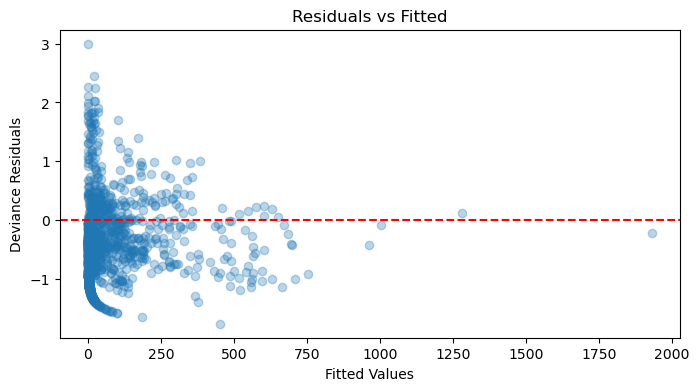

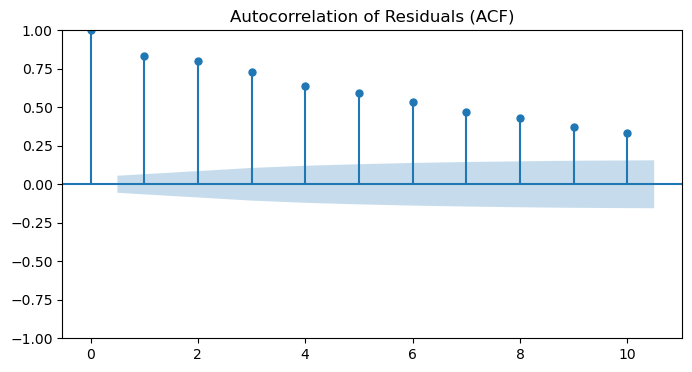

UV RR range: 0.000 to 1613.659


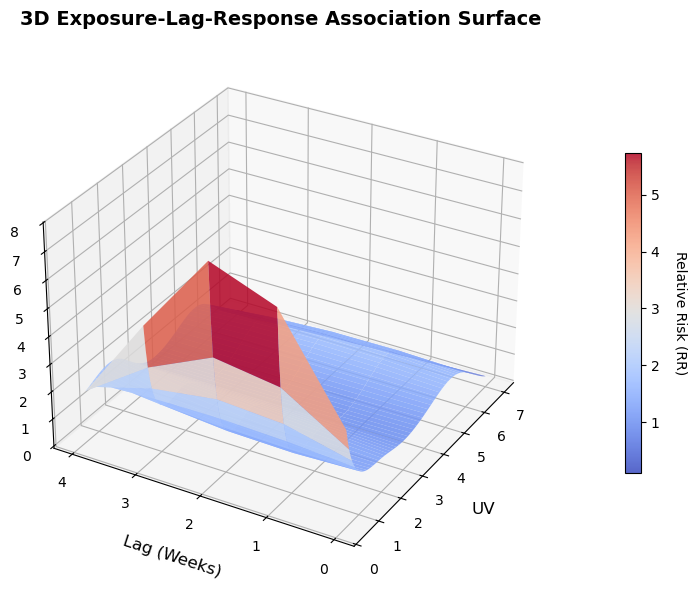

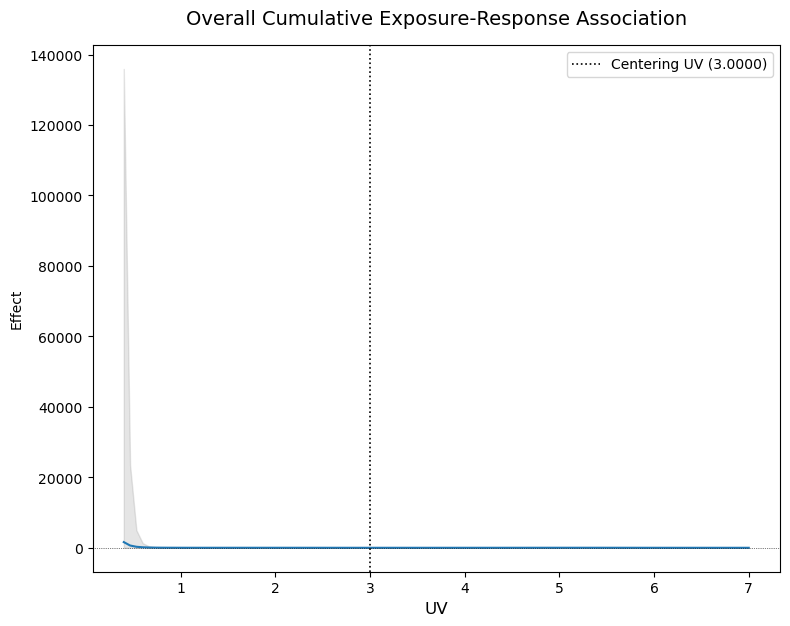

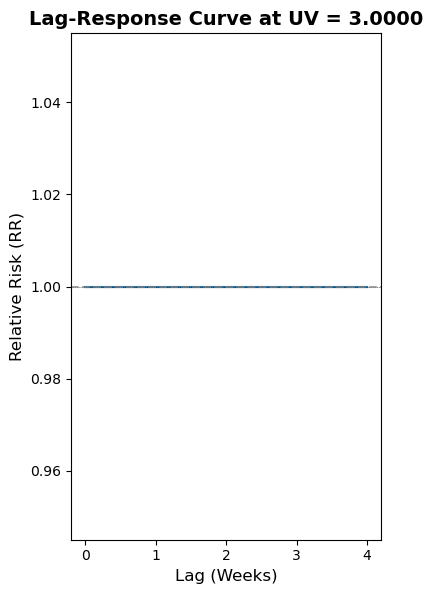

In [31]:
tar_var = "H1"

for exp in mete_col:
    exp_col_list = [exp]
    display(Markdown(f"**{'='*30} {exp} {'='*30}**"))
    result, pred, model_data, cb_list = DLNM(df, max_lag=4, tar_var=tar_var, exp_col_list=exp_col_list, linear_predictors_list=linear_predictors_list, bs_name_lst=bs_name_lst, ccs_name_lst=ccs_name_lst, cb_grid=cb_grid, smoother_grid=smoother_grid, disp_grid=disp_grid, criterion="bic")
